In [42]:
#Librerías

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import mlflow
import mlflow.sklearn
from IPython.display import Image

# Paso 1: Carga y describe el dataset

In [2]:
#Leer dataset
df = pd.read_csv("winequality-white.csv", sep=";")

#Imprimir primeras líneas de dataset
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
#Imprimir cantidad de registros y variables
print("Número de registros:", df.shape[0])
print("Número de variables:", df.shape[1])

Número de registros: 4898
Número de variables: 12


In [4]:
#Imprimir columnas del dataset
print(df.columns)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')


In [5]:
#Imprimir información de tipos de datos en cada columnas
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [6]:
#Revisar si hay datos NULL
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

fixed acidity:
Cantidad de ácidos fijos presentes en el vino.

volatile acidity:
Ácidos volátiles que pueden afectar negativamente el sabor.

citric acid:
Cantidad de ácido cítrico presente.

residual sugar:
Azúcar restante después de la fermentación.

chlorides:
Concentración de cloruros.

free sulfur dioxide:
Dióxido de azufre libre.

total sulfur dioxide:
Dióxido de azufre total.

density:
Densidad del vino.

pH:
Nivel de acidez.

sulphates:
Cantidad de sulfatos.

alcohol:
Porcentaje de alcohol.

quality:
Calificación de calidad del vino (variable objetivo).

El dataset Wine Quality White contiene registros de vinos blancos con 12 variables fisicoquímicas relacionadas con su composición. La variable objetivo es "quality", la cual representa una calificación de calidad del vino. Se realizó una inspección inicial utilizando pandas para revisar dimensiones, tipos de datos y posibles valores faltantes.

# Paso 2: Realiza un análisis exploratorio

In [7]:
#Imprimir tabla de estadísticas descriptivas
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


La tabla de estadísticas descriptivas proporciona una visión general de las características del conjunto de datos de vinos blancos. Se observa que el dataset contiene 4,898 registros para todas las variables, lo que confirma que no existen valores faltantes en las observaciones analizadas. La variable objetivo quality presenta una media de 5.88 y una desviación estándar de 0.89, indicando que la mayoría de los vinos se concentran alrededor de niveles de calidad intermedios. Asimismo, se observa que variables como residual sugar y total sulfur dioxide presentan desviaciones estándar relativamente altas en comparación con sus medias, lo que sugiere una mayor dispersión en sus valores.

Al comparar los valores mínimos y máximos, se identifican diferencias importantes entre algunas observaciones; por ejemplo, el contenido de azúcar residual varía desde 0.6 hasta 65.8, mientras que el dióxido de azufre total oscila entre 9 y 440, lo que indica una considerable heterogeneidad en las características químicas de los vinos analizados. Además, la comparación entre las medianas (50%) y las medias permite inferir que algunas variables presentan distribuciones asimétricas, especialmente aquellas relacionadas con el azúcar residual y los compuestos de azufre.

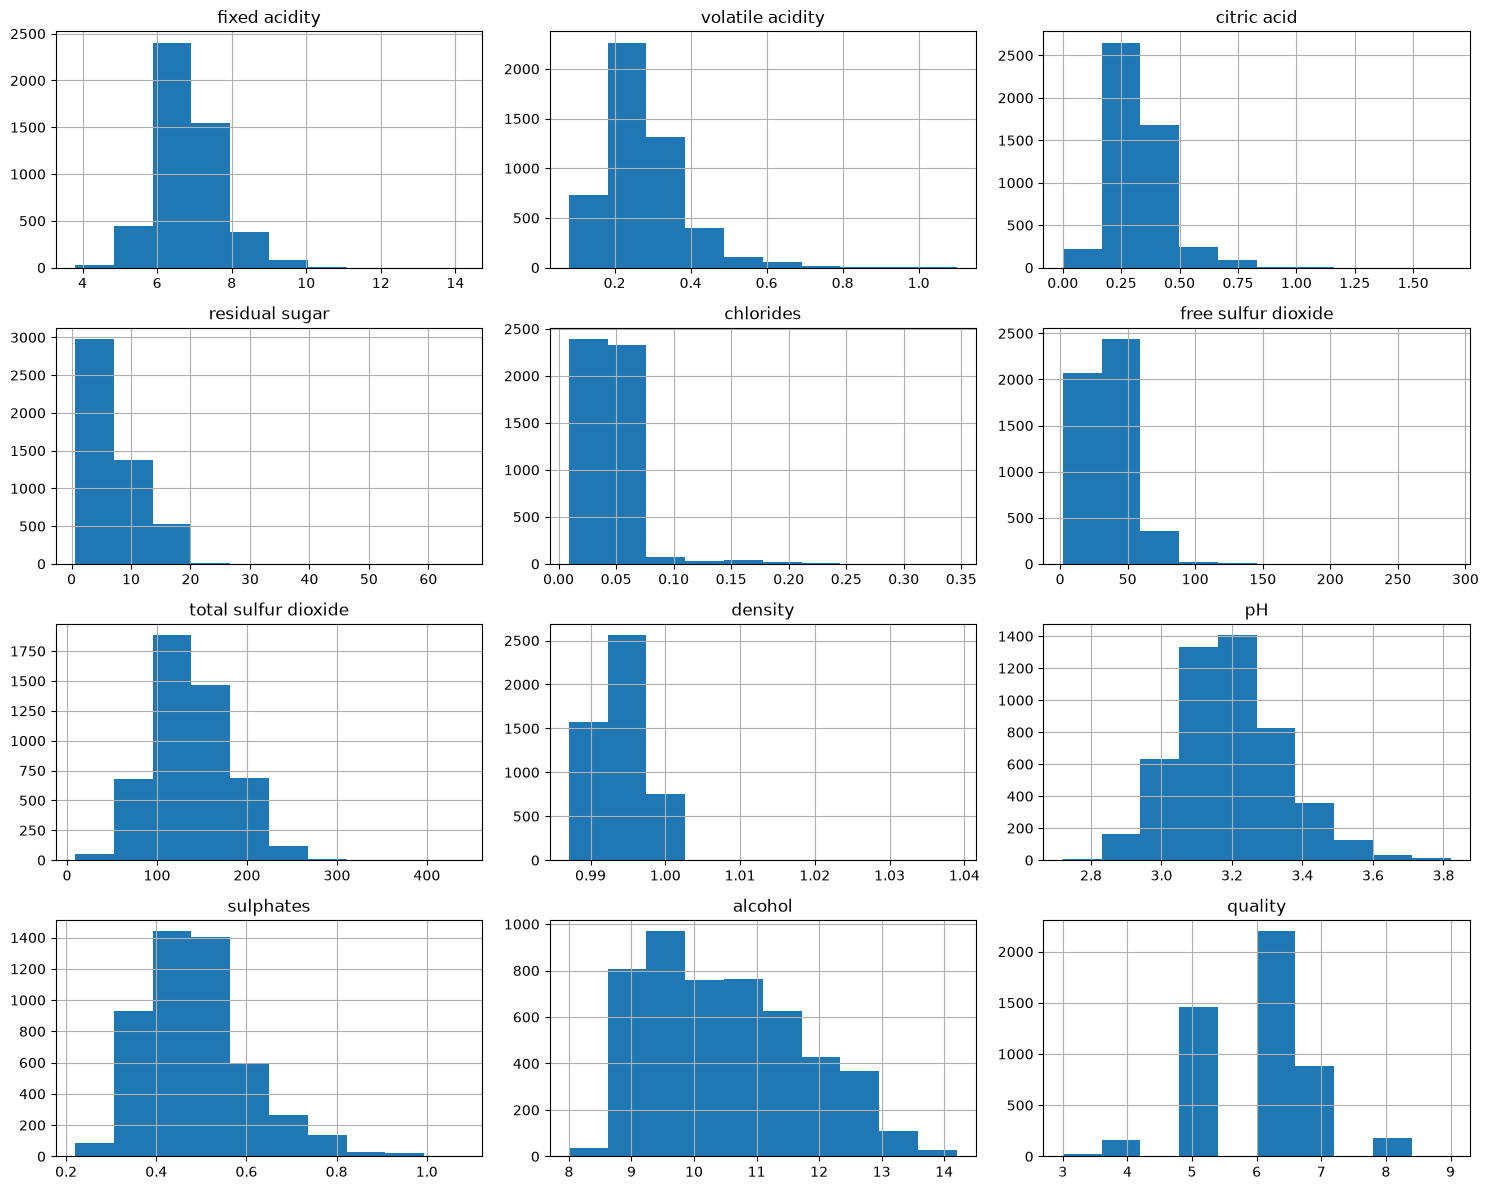

In [8]:
#Imprimir histogramas de distribución
df.hist(figsize=(15,12))

plt.tight_layout()
plt.show()

Se observa que variables como fixed acidity, citric acid, pH, density y sulphates presentan distribuciones relativamente concentradas alrededor de un valor central, lo que sugiere una mayor homogeneidad en estas mediciones dentro de los vinos analizados. Por otro lado, variables como residual sugar, chlorides, free sulfur dioxide y total sulfur dioxide muestran distribuciones asimétricas hacia la derecha, indicando la presencia de observaciones con valores significativamente mayores al promedio.

La variable alcohol presenta una distribución más dispersa, con una concentración importante entre los 9 y 12 grados alcohólicos, mientras que la variable objetivo quality muestra una clara acumulación en las calificaciones de 5 y 6, con una menor cantidad de observaciones en los extremos de la escala. Esto indica que la mayoría de los vinos del conjunto de datos poseen una calidad media, mientras que los vinos con calificaciones muy bajas o muy altas son menos frecuentes.

Asimismo, la presencia de colas largas en algunas distribuciones sugiere la existencia de posibles valores atípicos, especialmente en variables relacionadas con el contenido de azúcar residual y compuestos de azufre.

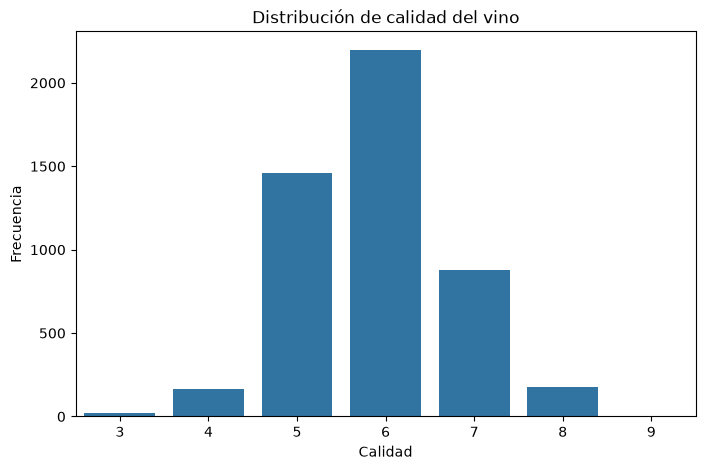

In [9]:
#Imprimir distribución de variable objetivo
plt.figure(figsize=(8,5))

sns.countplot(x=df["quality"])

plt.title("Distribución de calidad del vino")

plt.xlabel("Calidad")

plt.ylabel("Frecuencia")

plt.show()

Se observa que la mayoría de las observaciones se concentran en las categorías 5 y 6, siendo la calidad 6 la más frecuente; en contraste, las categorías extremas, como 3, 4, 8 y 9, cuentan con una cantidad considerablemente menor de registros. Esto indica que la mayor parte de los vinos evaluados posee una calidad media, mientras que los vinos de calidad muy baja o muy alta son menos comunes dentro de la muestra.

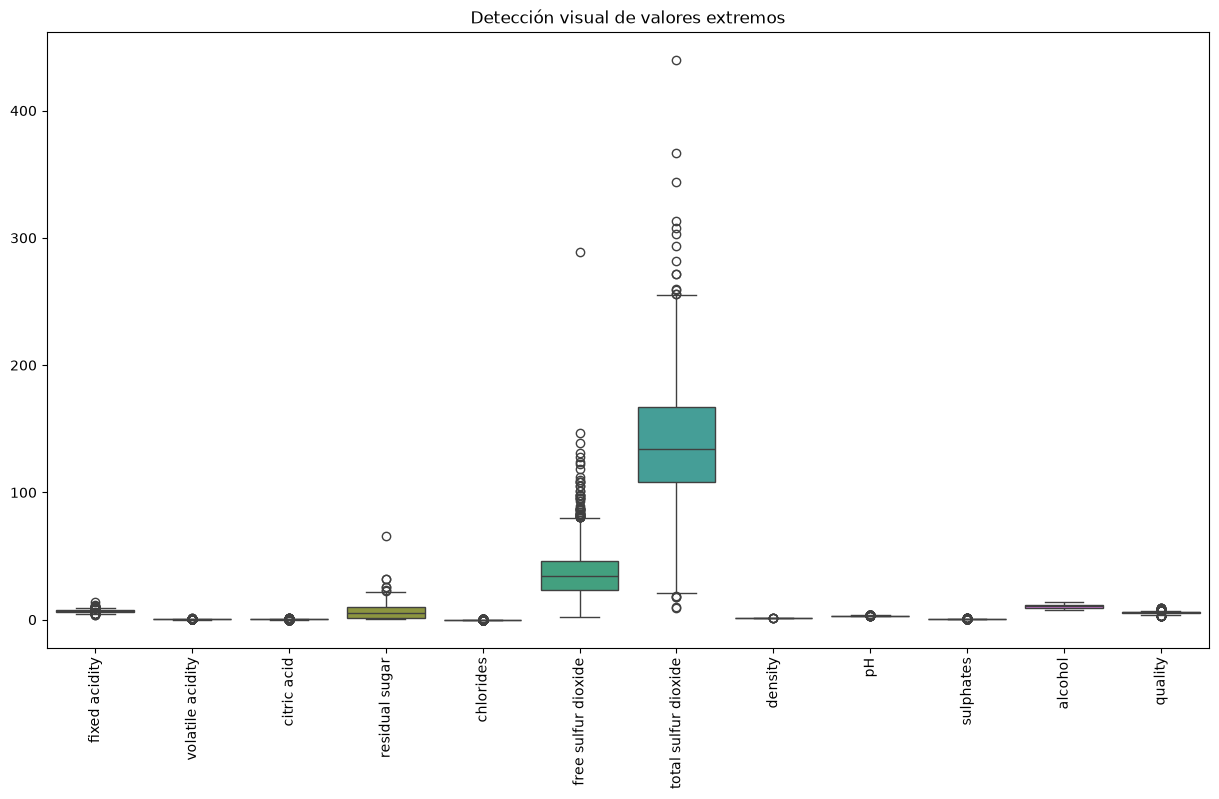

In [10]:
#Imprimir diagramas de caja con valores extremos
plt.figure(figsize=(15,8))

sns.boxplot(data=df)

plt.xticks(rotation=90)

plt.title("Detección visual de valores extremos")

plt.show()

En la gráfica se observa que varias variables presentan puntos fuera de los límites superiores e inferiores establecidos por el rango intercuartílico (IQR), lo que indica la existencia de valores extremos. Esta situación es especialmente notable en las variables free sulfur dioxide, total sulfur dioxide, residual sugar y, en menor medida, chlorides, donde se aprecia una cantidad considerable de observaciones alejadas del comportamiento central de los datos.

Las variables relacionadas con el contenido de dióxido de azufre presentan la mayor cantidad de valores atípicos, alcanzando en algunos casos niveles significativamente superiores a la mayoría de las observaciones. De igual forma, el azúcar residual muestra una dispersión considerable y varios registros con valores elevados. Por otro lado, variables como pH, density y alcohol presentan distribuciones más compactas y una menor presencia de observaciones extremas, lo que sugiere una mayor estabilidad en sus mediciones.

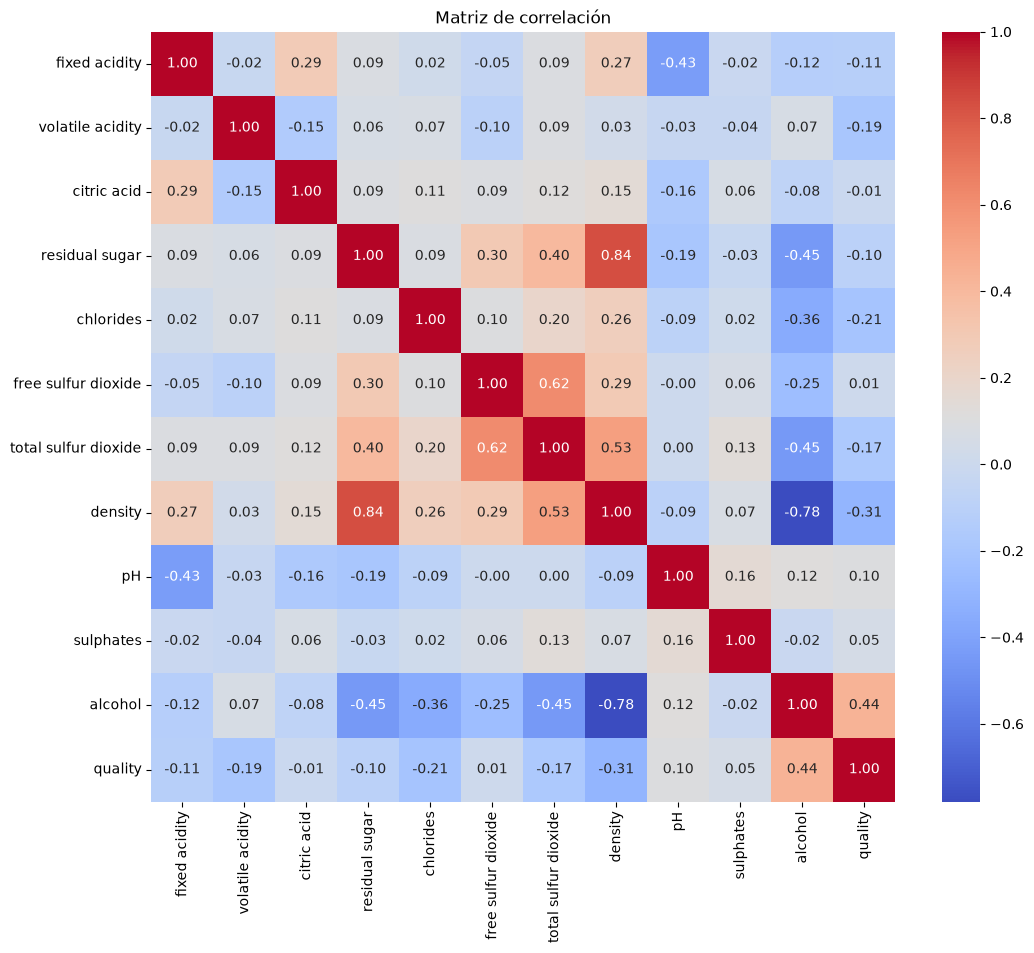

In [11]:
#Imprimir matriz de correlación
correlation_matrix = df.corr()

plt.figure(figsize=(12,10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación")

plt.show()

En general, se observa que la mayoría de las variables presentan correlaciones bajas o moderadas entre sí, lo que indica que cada característica aporta información relativamente independiente al conjunto de datos.

Entre las relaciones más destacadas se encuentra la fuerte correlación positiva entre residual sugar y density (0.84), lo que sugiere que los vinos con un mayor contenido de azúcar residual tienden a presentar una densidad más elevada. También se aprecia una correlación positiva considerable entre free sulfur dioxide y total sulfur dioxide (0.62), ya que ambas variables representan mediciones relacionadas con la presencia de compuestos de azufre en el vino. Por otro lado, destaca la fuerte correlación negativa entre density y alcohol (-0.78), indicando que los vinos con mayor contenido alcohólico suelen presentar una menor densidad.

Respecto a la variable objetivo quality, la relación positiva más notable corresponde a alcohol (0.44), lo que sugiere que vinos con un mayor porcentaje de alcohol tienden a recibir mejores calificaciones. En contraste, density presenta una correlación negativa moderada (-0.31), mientras que chlorides (-0.21), volatile acidity (-0.19) y total sulfur dioxide (-0.17) muestran correlaciones negativas de menor magnitud. Aunque ninguna variable posee una correlación extremadamente alta con la calidad, estos resultados permiten identificar cuáles características podrían tener una mayor influencia en las predicciones del modelo.

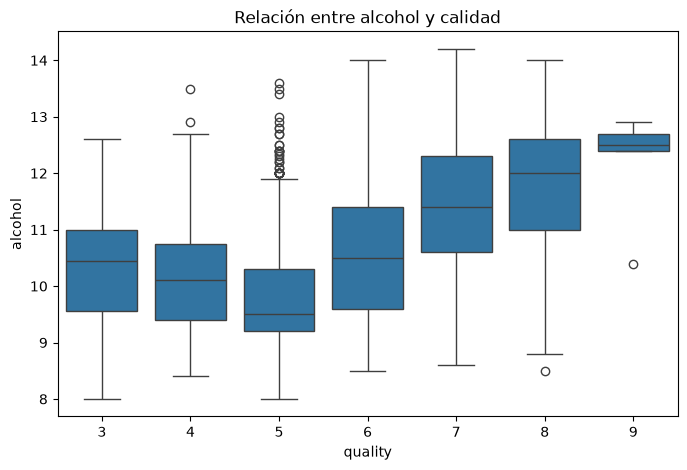

In [12]:
#Imprimir diagramas de cajas con relación con variable objetivo
plt.figure(figsize=(8,5))

sns.boxplot(
    x="quality",
    y="alcohol",
    data=df
)

plt.title("Relación entre alcohol y calidad")

plt.show()

La gráfica de cajas muestra una relación positiva entre el contenido de alcohol y la calidad del vino, ya que a medida que aumenta la calificación de calidad también tiende a incrementarse la mediana del porcentaje de alcohol. Los vinos con calidades más bajas (3, 4 y 5) presentan niveles de alcohol generalmente menores, mientras que las categorías de mayor calidad (7, 8 y 9) muestran medianas considerablemente más altas y concentradas en valores superiores. Aunque existe variabilidad dentro de cada nivel de calidad y se observan algunos valores atípicos, la tendencia general es que los vinos mejor valorados suelen tener un mayor contenido alcohólico.

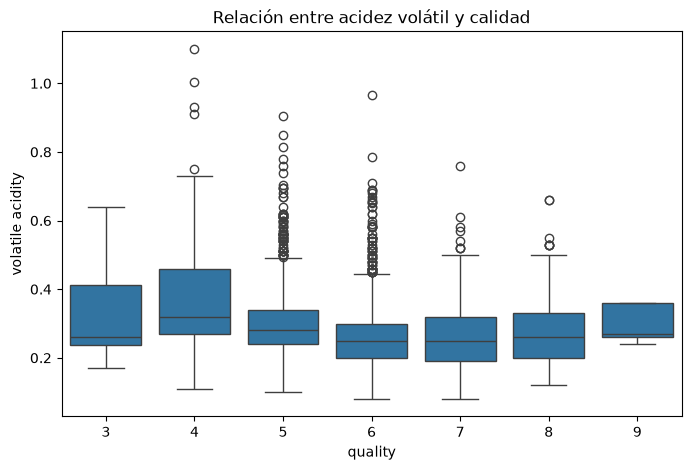

In [13]:
#Imprimir diagramas de cajas con relación con variable objetivo
plt.figure(figsize=(8,5))

sns.boxplot(
    x="quality",
    y="volatile acidity",
    data=df
)

plt.title("Relación entre acidez volátil y calidad")

plt.show()

La gráfica de cajas muestra la relación entre la acidez volátil (volatile acidity) y la calidad del vino. Se observa una tendencia general a que los vinos con mayores niveles de calidad presenten valores más bajos de acidez volátil, mientras que las categorías de menor calidad exhiben una mayor dispersión y concentraciones más elevadas de esta característica. Aunque existen valores atípicos en prácticamente todas las categorías, la mediana de la acidez volátil tiende a disminuir conforme aumenta la calidad del vino, especialmente entre las calificaciones 4, 5 y 6.

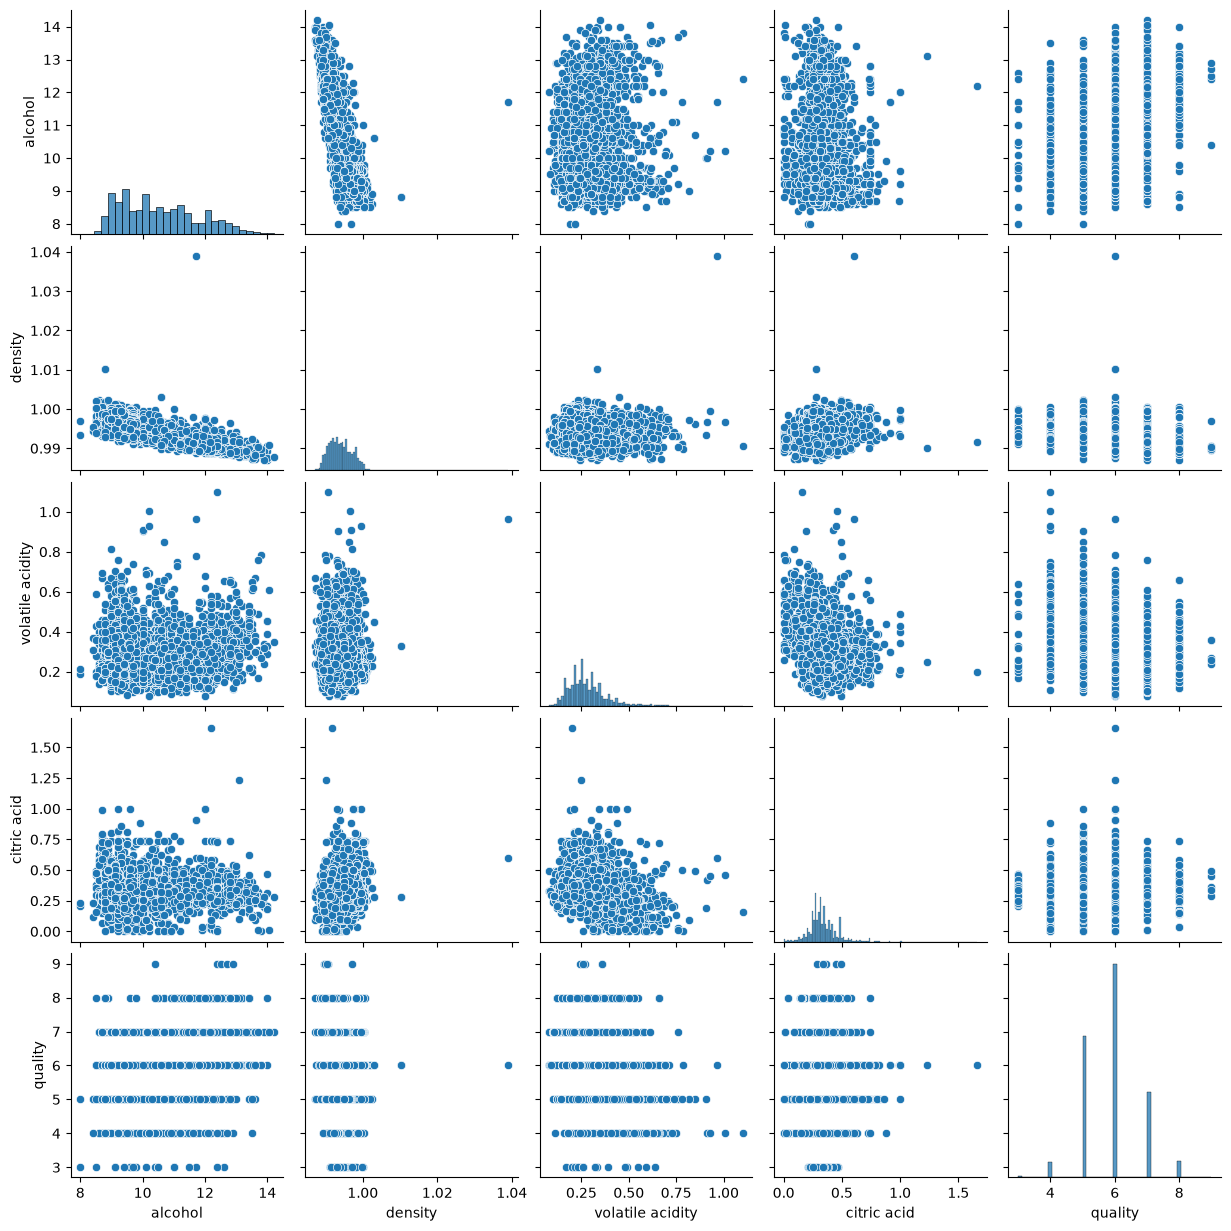

In [14]:
#Imprimir matriz de dispersión
variables = [
    "alcohol",
    "density",
    "volatile acidity",
    "citric acid",
    "quality"
]

sns.pairplot(df[variables])

plt.show()

Se observa una relación negativa marcada entre alcohol y density, donde los vinos con mayor contenido alcohólico tienden a presentar una menor densidad, comportamiento consistente con los resultados observados en la matriz de correlación. Asimismo, la variable quality muestra una tendencia a concentrarse en valores más altos de alcohol y en densidades ligeramente menores, lo que refuerza la idea de que estas características pueden influir en la calidad percibida del vino. En contraste, las relaciones entre volatile acidity, citric acid y quality son menos evidentes visualmente, aunque se aprecia una ligera tendencia de los vinos con mejor calidad a presentar menores niveles de acidez volátil. Los histogramas ubicados en la diagonal confirman las distribuciones observadas previamente, mostrando una concentración de registros en valores específicos de calidad y una dispersión moderada en las variables químicas analizadas.

Se realizó un análisis exploratorio de datos utilizando estadísticas descriptivas y visualizaciones. Se analizaron las distribuciones individuales de las variables mediante histogramas, identificando sus rangos y comportamientos. Se evaluó la presencia de valores extremos mediante diagramas de caja. Posteriormente se construyó una matriz de correlación para identificar relaciones entre variables y con la variable objetivo quality. Finalmente se exploraron visualmente relaciones específicas entre alcohol, acidez volátil y calidad del vino, así como un conjunto reducido de variables mediante pairplots para observar tendencias generales.

# Paso 3: Limpia los datos

In [15]:
#Copia de datos para limpieza
df_clean = df.copy()

In [16]:
#Revisión de datos NULL
df_clean.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Se revisó la existencia de valores faltantes utilizando isnull().sum(). No se identificaron valores faltantes, por lo que no fue necesario realizar imputaciones.

In [17]:
#Revisión de tipos de datos
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


Se verificaron los tipos de datos utilizando df.info(). Todas las variables presentaban tipos numéricos adecuados para el análisis y modelado posterior.

In [18]:
#Revisar datos duplicados
df_clean.duplicated().sum()

np.int64(937)

In [19]:
#Eliminar datos duplicados
df_clean = df_clean.drop_duplicates()

In [20]:
#Revisar datos duplicados
df_clean.duplicated().sum()

np.int64(0)

Se identificaron registros duplicados mediante duplicated().sum(). Los registros duplicados fueron eliminados utilizando drop_duplicates() para evitar sesgos en el entrenamiento del modelo.

In [40]:
#Imprimir tamaño de dataset limpio
print("Dataset limpio:")
print(df_clean.shape)

Dataset limpio:
(3961, 12)


In [22]:
#Calcular outliers
Q1 = df_clean.quantile(0.25)
Q3 = df_clean.quantile(0.75)

IQR = Q3 - Q1

outliers = (
    (df_clean < (Q1 - 1.5 * IQR)) |
    (df_clean > (Q3 + 1.5 * IQR))
)

outliers.sum()

fixed acidity           106
volatile acidity        133
citric acid             223
residual sugar           16
chlorides               178
free sulfur dioxide      44
total sulfur dioxide     14
density                   6
pH                       46
sulphates                96
alcohol                   0
quality                 156
dtype: int64

In [23]:
#Limpiar outliers
for column in df_clean.columns:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_clean[column] = df_clean[column].clip(lower, upper)

Se detectaron valores atípicos mediante el método del rango intercuartílico (IQR). Para evitar la pérdida significativa de información, los outliers fueron tratados mediante capping, limitando los valores al rango permitido por el método IQR.

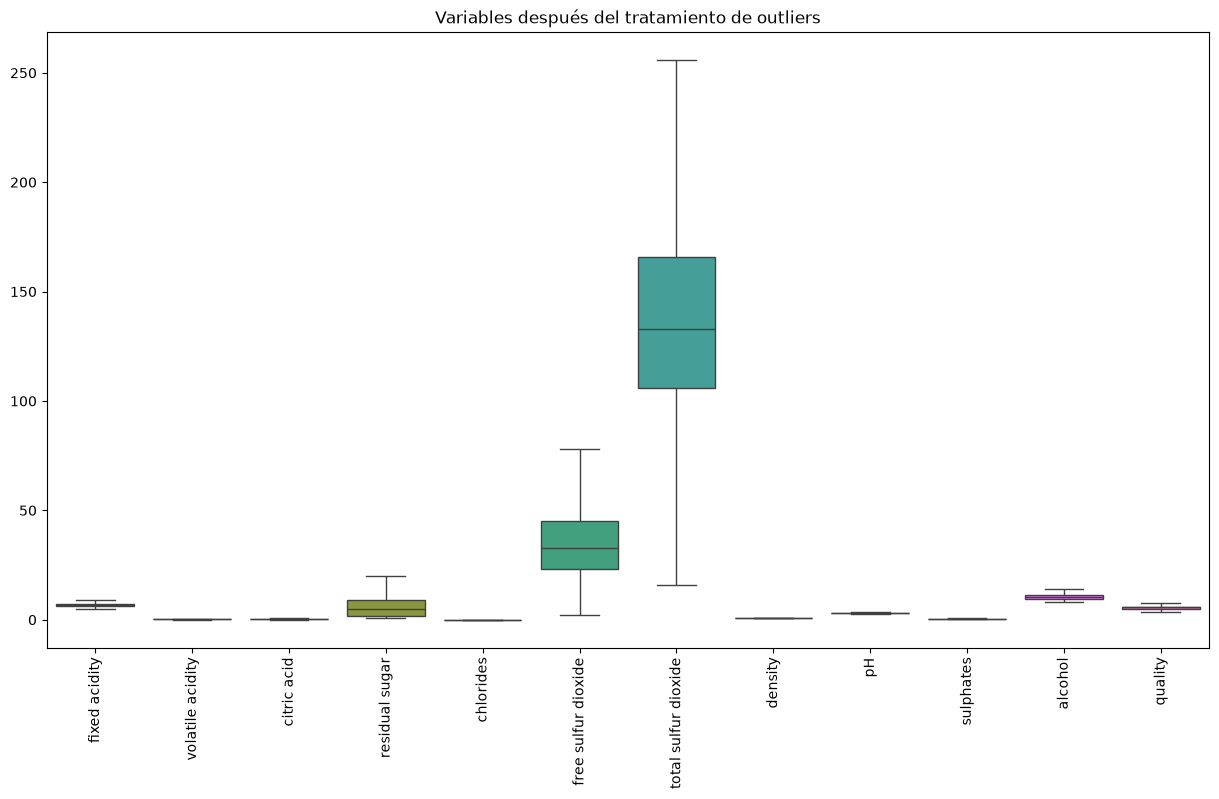

In [24]:
#Diagrama de cajas posterior a limpieza de outliers
plt.figure(figsize=(15,8))

sns.boxplot(data=df_clean)

plt.xticks(rotation=90)

plt.title("Variables después del tratamiento de outliers")

plt.show()

Observando la gráfica, las variables que originalmente presentaban una gran cantidad de valores extremos, como free sulfur dioxide, total sulfur dioxide y residual sugar, muestran ahora distribuciones más controladas y consistentes. Este resultado sugiere que el tratamiento aplicado logró reducir la influencia de observaciones atípicas que podrían afectar negativamente al modelo, al mismo tiempo que conservó la mayor parte de la información disponible en el dataset.

In [25]:
#Guardar dataset limpio
df_clean.to_csv(
    "winequality_clean.csv",
    index=False
)

# Paso 4: Entrena un modelo base

In [26]:
#Leer dataset limpio
df_model = pd.read_csv("winequality_clean.csv")

#Imprimir primeras lineas de dataset limpio
df_model.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,19.85,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6.0
1,6.3,0.30,0.34,1.60,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6.0
2,8.1,0.28,0.40,6.90,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6.0
3,7.2,0.23,0.32,8.50,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0
4,6.2,0.32,0.16,7.00,0.045,30.0,136.0,0.9949,3.18,0.47,9.6,6.0


In [27]:
#Definición de variables predictoras y variable objetivo
X = df_model.drop("quality", axis=1)

y = df_model["quality"]

In [28]:
print("Variables predictoras:", X.shape)
print("Variable objetivo:", y.shape)

Variables predictoras: (3961, 11)
Variable objetivo: (3961,)


In [29]:
#División de datos para train y test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

El conjunto de datos fue dividido utilizando una estrategia hold-out con 80% de observaciones para entrenamiento y 20% para prueba, empleando una semilla aleatoria (random_state=42) para asegurar la reproducibilidad de los resultados.

In [30]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3168, 11)
X_test: (793, 11)
y_train: (3168,)
y_test: (793,)


In [31]:
#Definición de modelo base
baseline_model = RandomForestRegressor(
    random_state=42
)

Se seleccionó Random Forest Regressor como modelo base debido a que es un algoritmo robusto para variables numéricas, requiere poca preparación de datos y permite obtener una línea base de desempeño para el problema de predicción de calidad del vino.

In [41]:
#Entrenamiento de modelo
baseline_model.fit(
    X_train,
    y_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [33]:
print("Modelo entrenado correctamente")

Modelo entrenado correctamente


El modelo fue entrenado utilizando las variables fisicoquímicas del vino como variables predictoras y la variable quality como objetivo.

# Paso 5: Evalúa el modelo

In [34]:
#Predicción del modelo base
y_pred = baseline_model.predict(X_test)

In [35]:
#Métricas de evaluación del modelo
rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print("RMSE:", rmse)
print("R2:", r2)

RMSE: 0.6917886698134188
R2: 0.34639266435512706


El modelo obtuvo un RMSE de 0.692, lo que indica que, en promedio, las predicciones de calidad del vino difieren aproximadamente 0.69 puntos respecto a la calificación real. Considerando que la variable quality se encuentra en una escala relativamente pequeña (valores enteros cercanos entre sí), el error obtenido es razonable para un modelo baseline y muestra que el modelo logra aproximarse a los valores observados, aunque todavía existe margen de mejora.

El modelo alcanzó un R² de 0.346, lo que significa que aproximadamente 34.6% de la variabilidad de la calidad del vino puede explicarse mediante las variables fisicoquímicas utilizadas en el entrenamiento. Aunque el porcentaje no es muy alto, es un resultado aceptable para un modelo base, cuyo propósito es establecer un punto de referencia inicial antes de realizar optimizaciones más avanzadas.

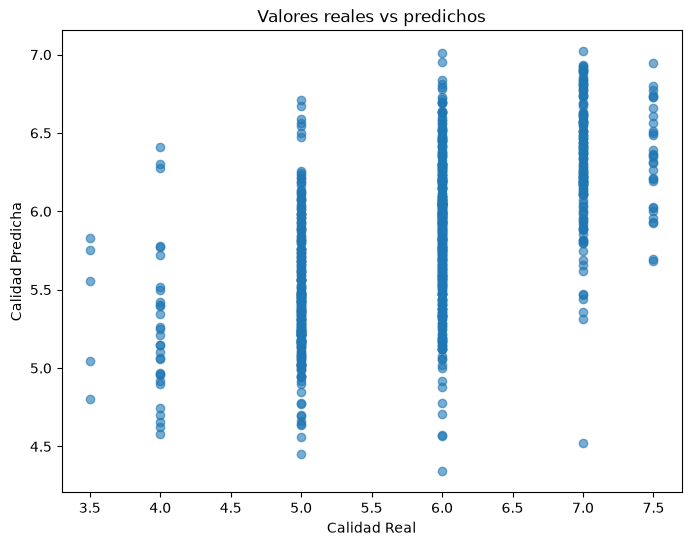

In [36]:
#Gráfica de valores reales vs predichos
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.xlabel("Calidad Real")
plt.ylabel("Calidad Predicha")

plt.title("Valores reales vs predichos")

plt.show()

En la gráfica de valores reales versus predichos se observa que el modelo es capaz de seguir parcialmente la tendencia general de los datos. Sin embargo, las predicciones se concentran principalmente entre valores cercanos a 5 y 7, lo que indica que el modelo tiene dificultad para representar completamente la variabilidad de la calidad real. Esto es consistente con el valor de R² obtenido, ya que explica una parte moderada de la variación presente en los datos.

# Paso 6: Registra el experimento en MLFlow

In [37]:
#Crear run de MLFlow
with mlflow.start_run():

    mlflow.log_param(
        "model",
        "RandomForestRegressor"
    )

    mlflow.log_param(
        "random_state",
        42
    )

    mlflow.log_metric(
        "RMSE",
        rmse
    )

    mlflow.log_metric(
        "R2",
        r2
    )

In [38]:
with mlflow.start_run():

    mlflow.log_param(
        "model",
        "RandomForestRegressor"
    )

    mlflow.log_param(
        "random_state",
        42
    )

    mlflow.log_metric(
        "RMSE",
        rmse
    )

    mlflow.log_metric(
        "R2",
        r2
    )
    #Se utiliza este formato para integrar métricas en MLFlow
    mlflow.sklearn.log_model(
    sk_model=baseline_model,
    artifact_path="wine_quality_model",
    registered_model_name=None,
    metadata=None,
    serialization_format="cloudpickle",
    skops_trusted_types=[
        "sklearn.tree._tree.Tree"
    ]
)

2026/10/04 10:49:23 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/04 10:49:23 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


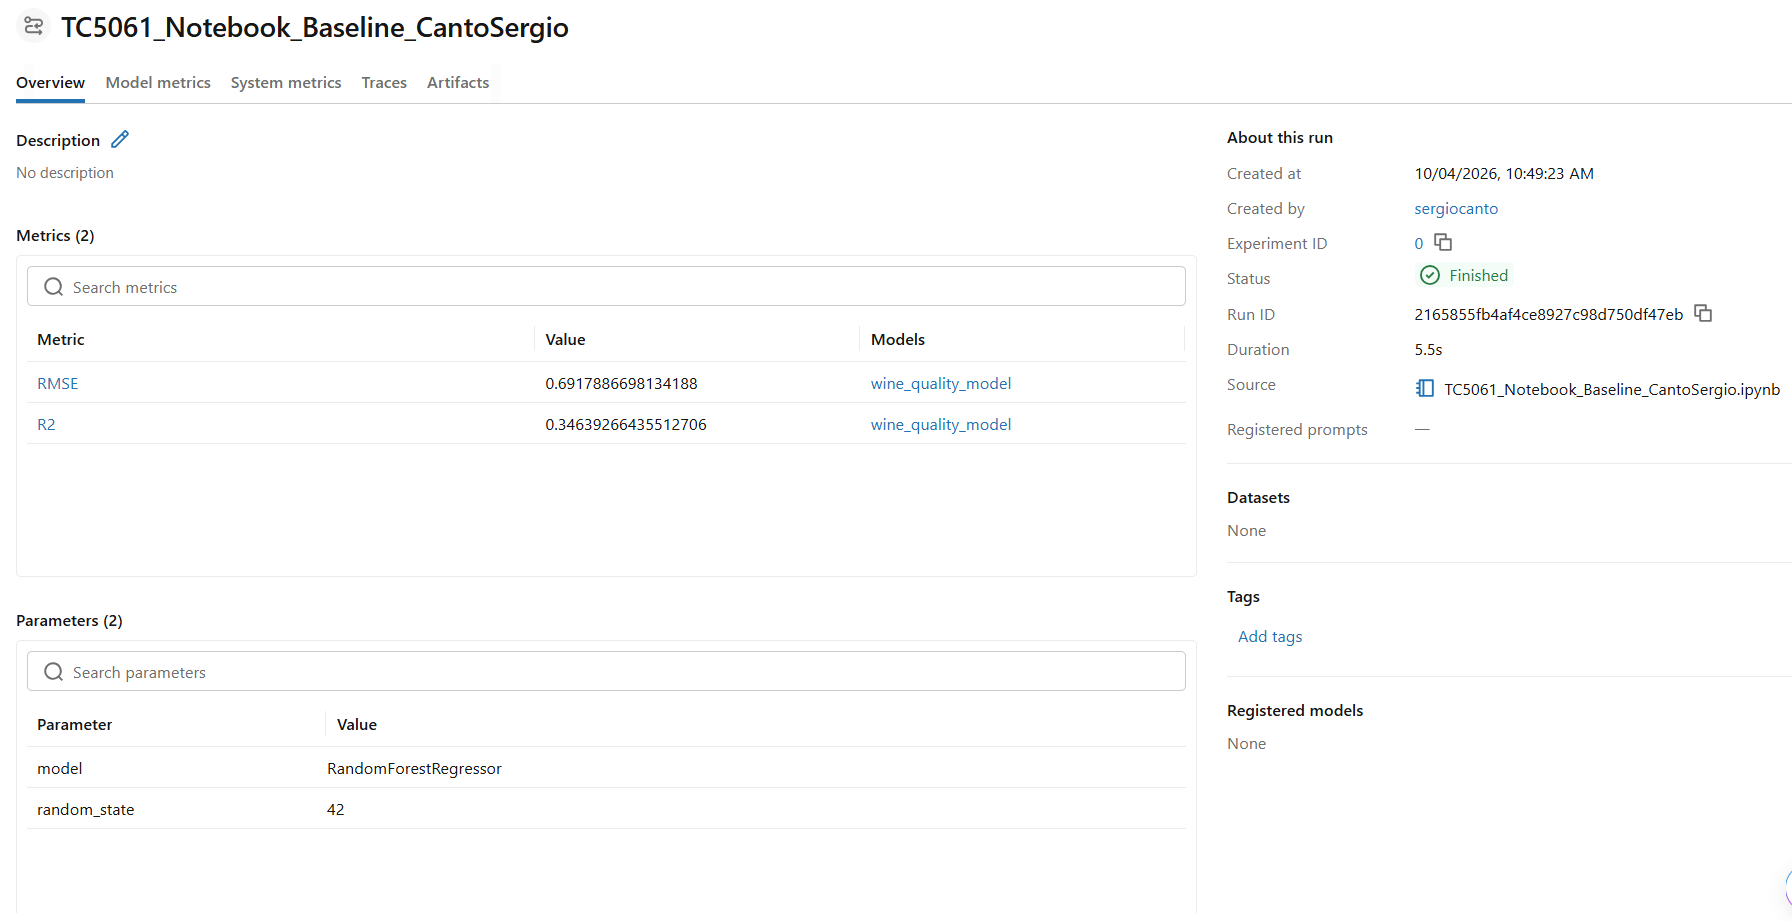

In [47]:
Image("Image1.png")

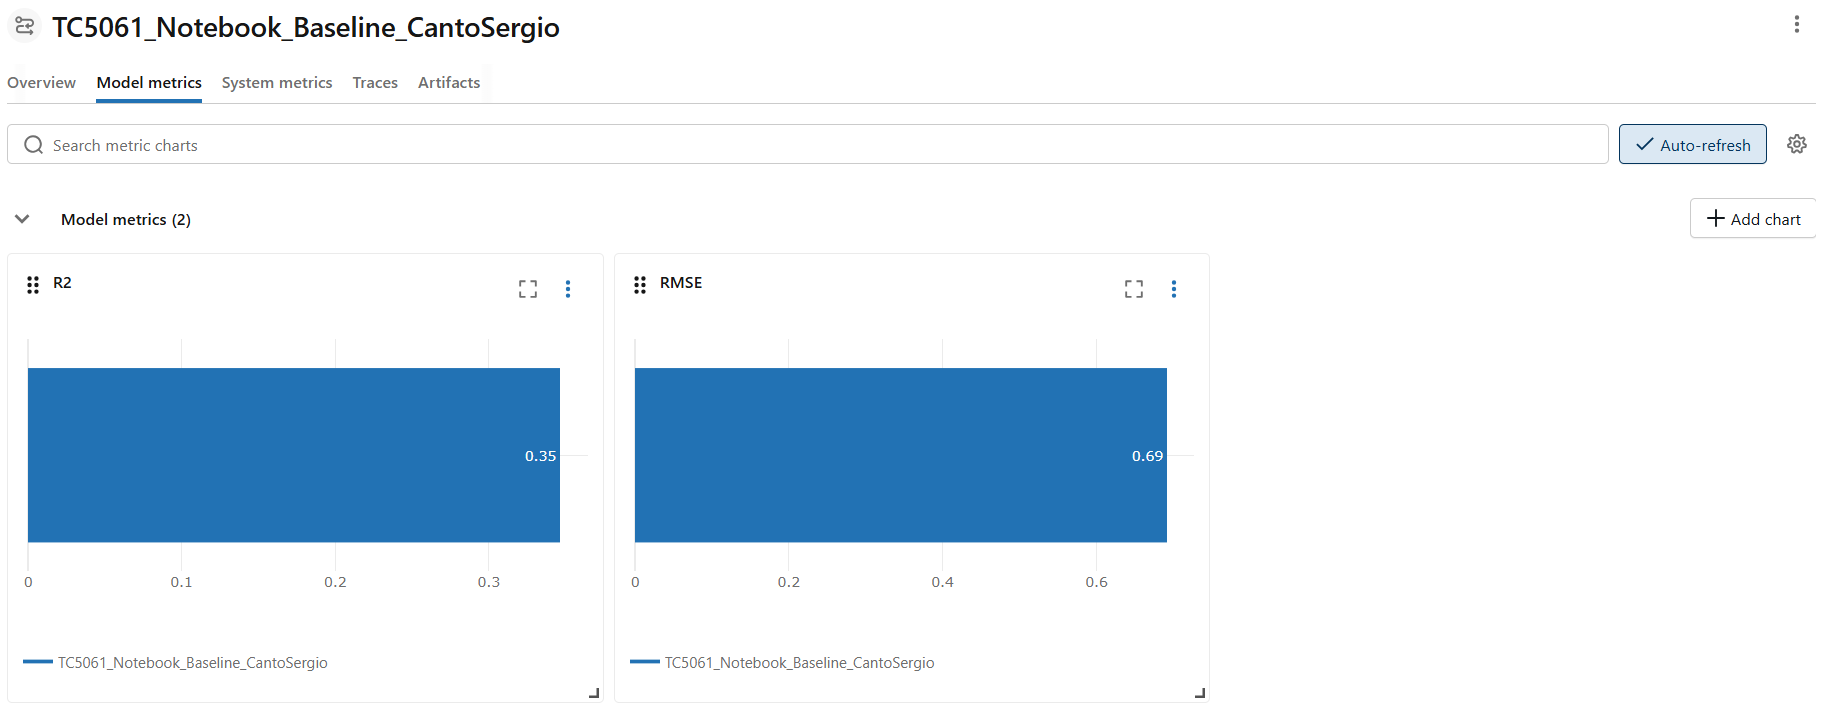

In [48]:
Image("Image2.png")

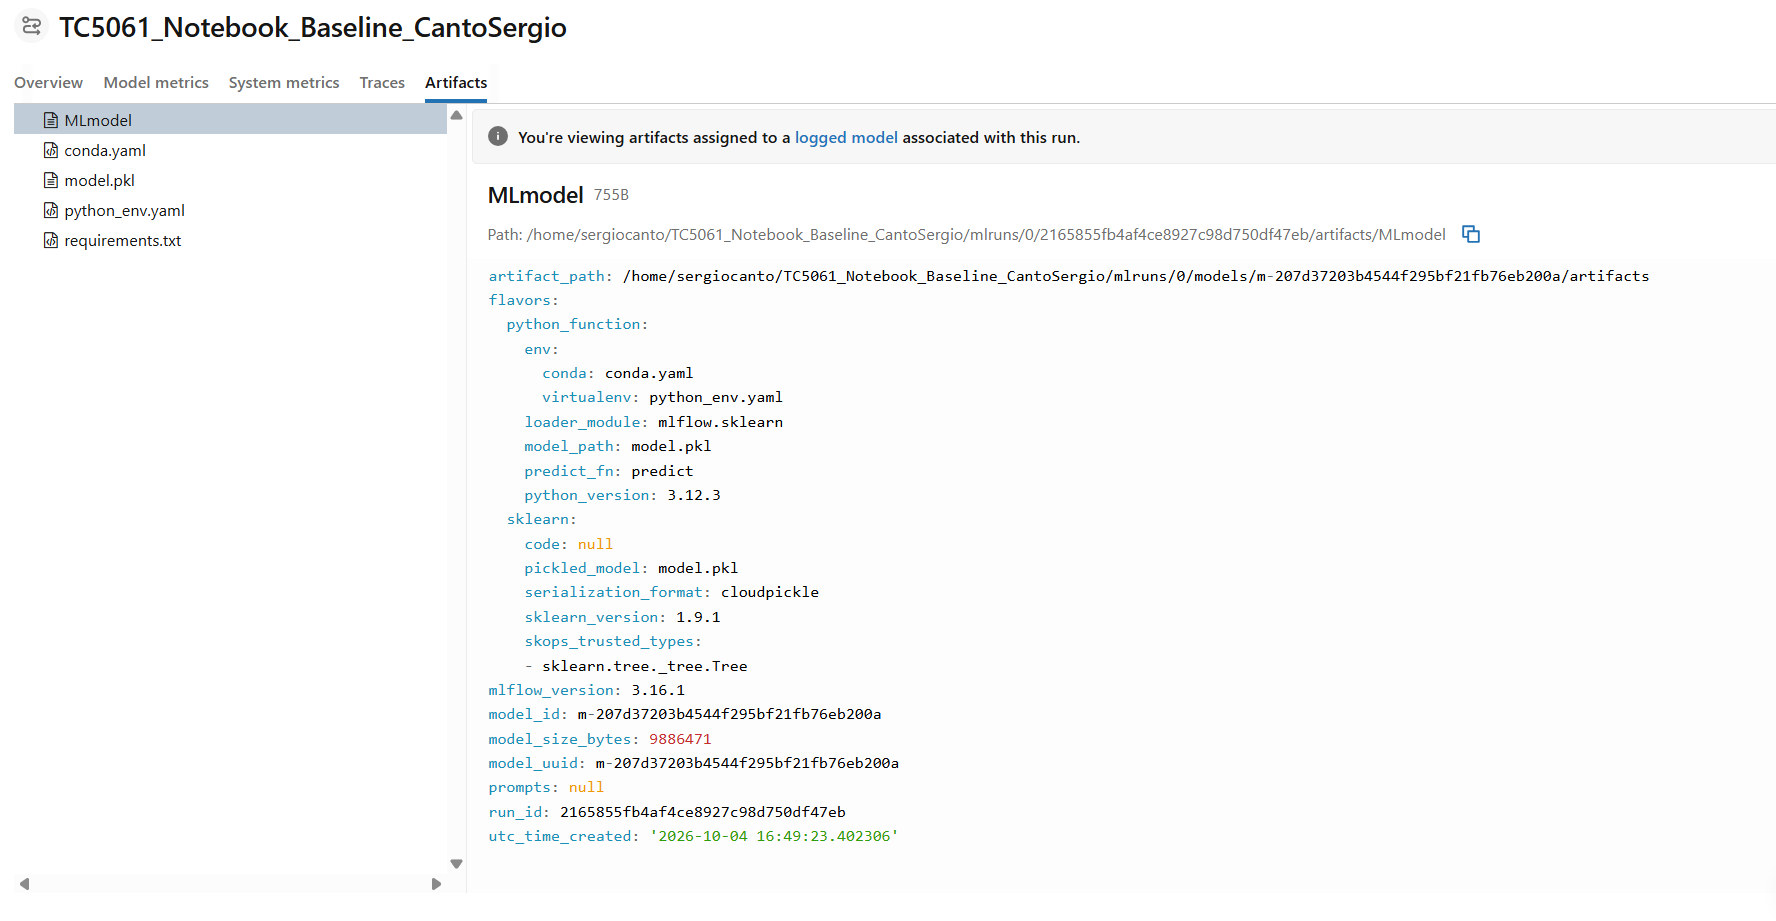

In [49]:
Image("Image3.png")

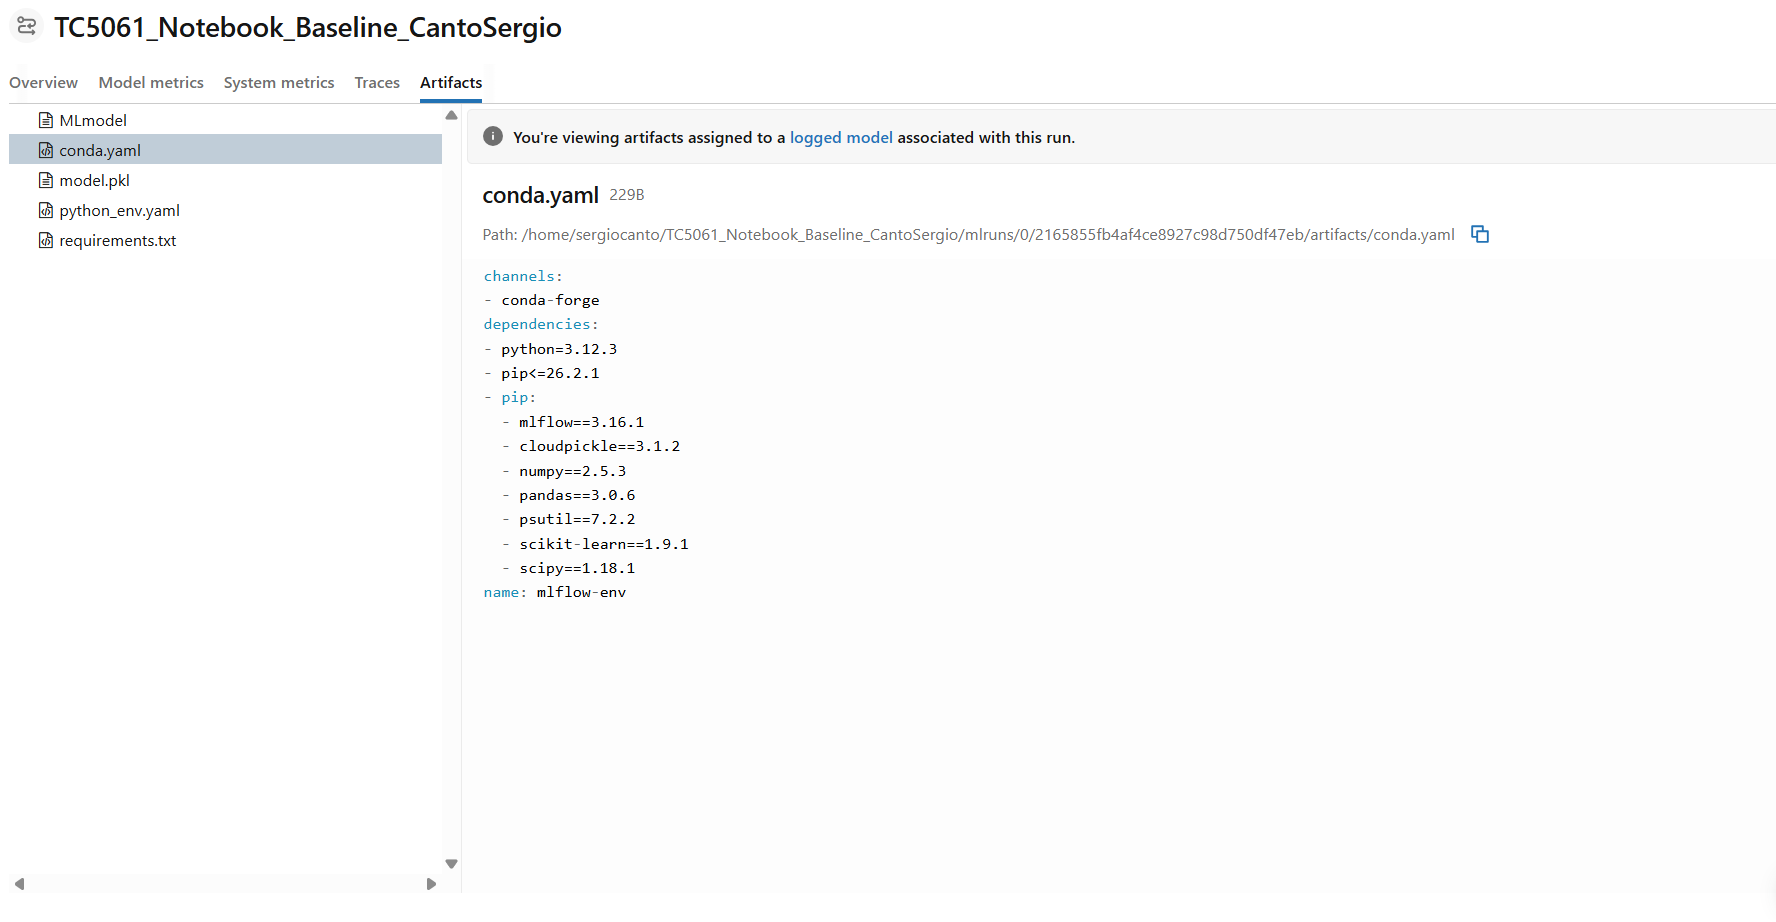

In [50]:
Image("Image4.png")

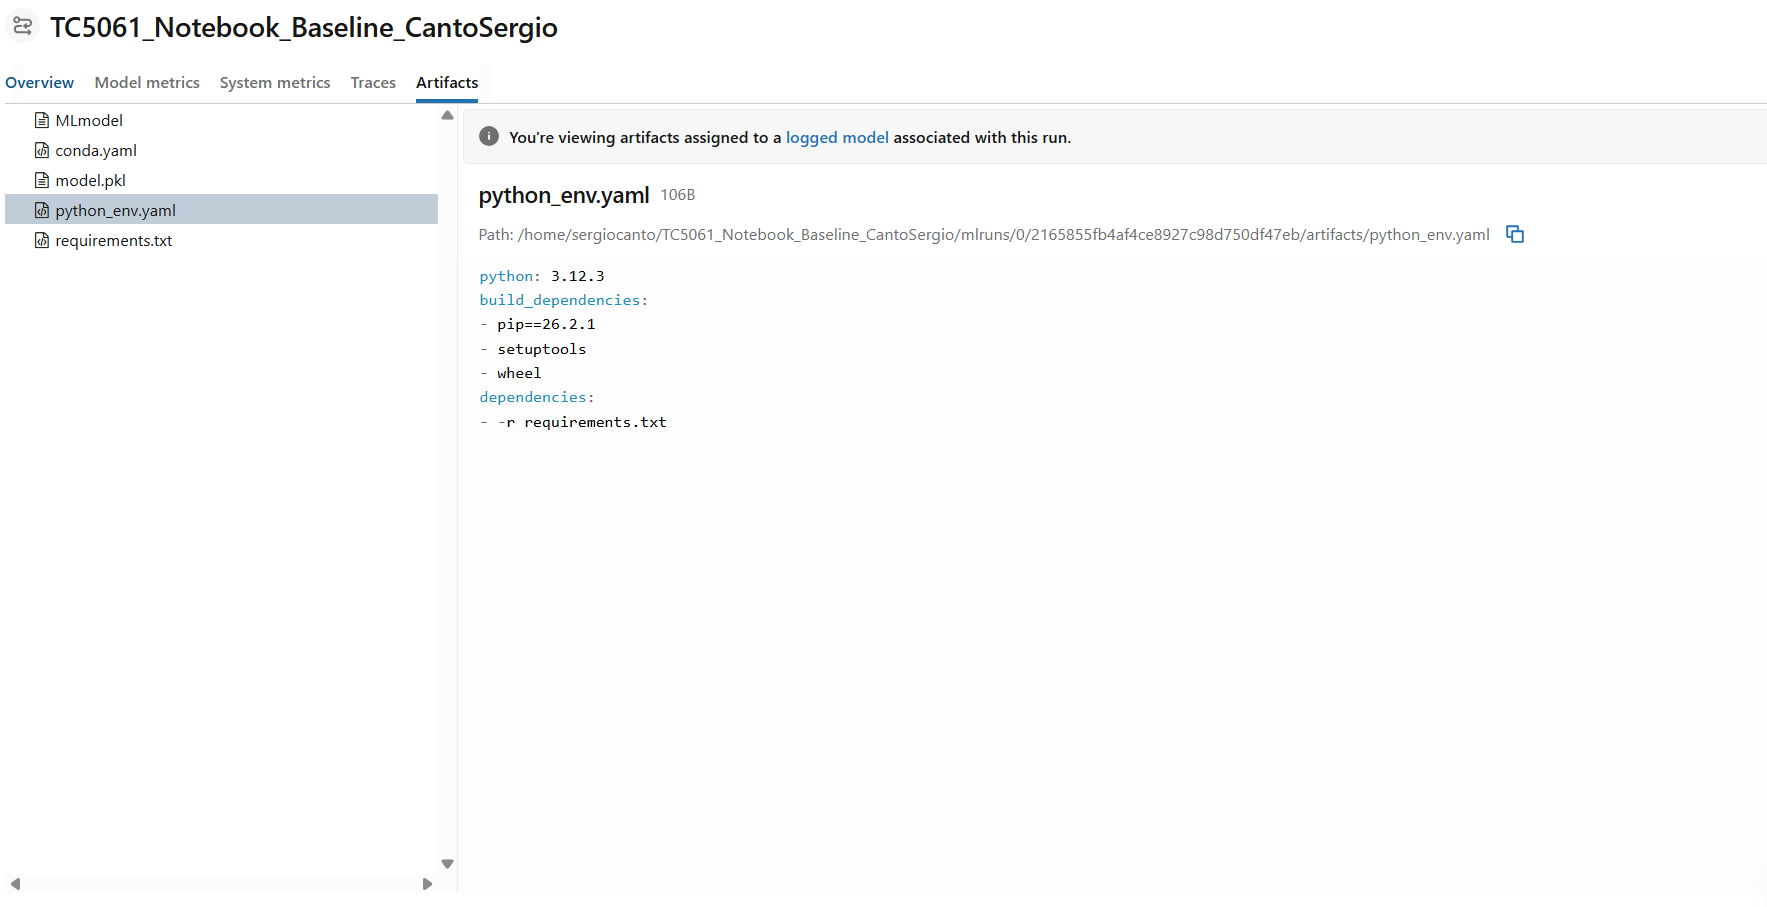

In [51]:
Image("Image5.png")

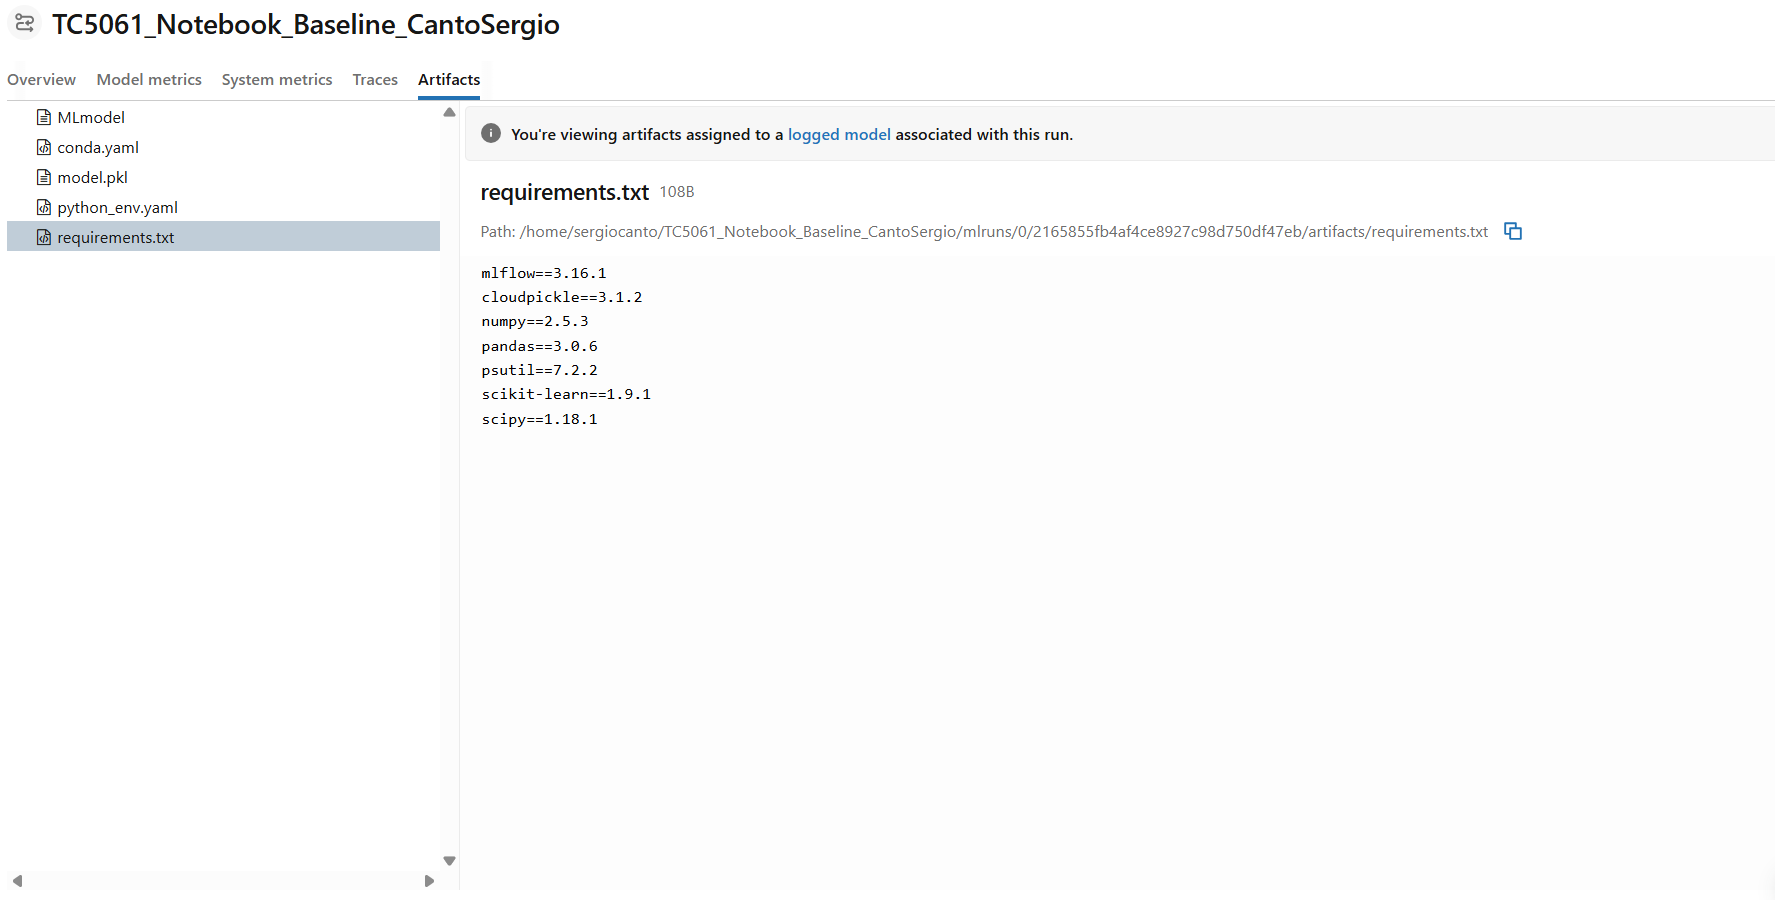

In [52]:
Image("Image6.png")

# Paso 7: Redacta una reflexión

Durante esta actividad pude recorrer las etapas fundamentales de un proyecto de Machine Learning, desde la exploración y limpieza de los datos hasta el entrenamiento, evaluación y registro de un modelo base utilizando MLflow; aunque el modelo Random Forest Regressor logró obtener resultados razonables (RMSE = 0.6918 y R² = 0.3464), considero que existen varias oportunidades de mejora desde la perspectiva de MLOps.

En primer lugar, automatizaría el flujo completo mediante pipelines reproducibles para evitar la ejecución manual de cada etapa; también incorporaría control de versiones para datos, código y modelos, permitiendo rastrear cambios y comparar experimentos de manera más eficiente. Otra mejora importante sería realizar un proceso sistemático de ajuste de hiperparámetros para optimizar el desempeño del modelo y registrar automáticamente cada experimento en MLflow para facilitar la trazabilidad; además, implementaría validaciones automatizadas de calidad de datos antes del entrenamiento y mecanismos de monitoreo para detectar degradación del modelo una vez desplegado.

Dentro de mi área profesional como ingeniero de hardware, estos aprendizajes son relevantes porque muchos sistemas modernos generan grandes cantidades de datos provenientes de sensores, pruebas de validación y procesos de manufactura. La aplicación de prácticas de Machine Learning y MLOps permitiría analizar dichos datos de manera más eficiente, detectar anomalías, predecir fallas y mejorar la toma de decisiones basada en evidencia; asimismo, conceptos como reproducibilidad, automatización y trazabilidad son principios que también se aplican en el desarrollo de productos de hardware, donde es fundamental mantener control sobre cambios, configuraciones y resultados de pruebas; por eso, considero que los conocimientos adquiridos en esta actividad tienen una aplicación directa en proyectos futuros relacionados con ingeniería, análisis de datos y mejora continua.